# Flood-It!: A/B test of ad frequency (Firebase experiment 1)

**Question.** Does the frequency of ads change whether new players come back?

**Design.** Firebase A/B Testing randomly assigned players to 4 variants of the Remote Config
parameter `ad_frequency`: variant 0 = 4 (control), 1 = 2, 2 = 8, 3 = 16.
The exact meaning of the number is not documented. Most likely it is "an ad every N levels",
so a higher number means fewer ads. This is an **assumption**.

**Metrics.**
- Primary: **D7 retention** (active on day 7 after day 0).
- Guardrails: **D1 retention**, **minutes played in the first 7 days**.

**Input.** `data/07_experiment_users.csv`: one row per experiment participant, built in BigQuery
with `sql/07_experiment_users.sql`. "Active" = a `session_start` or `user_engagement` event that day.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
RNG = np.random.default_rng(42)
VARIANT_LABEL = {0: '0: ad_frequency 4 (control)', 1: '1: ad_frequency 2',
                 2: '2: ad_frequency 8', 3: '3: ad_frequency 16'}

df = pd.read_csv('../data/07_experiment_users.csv', parse_dates=['exposure_date', 'install_date'])
df.shape

(4924, 13)

## 1. Who is in the data

Day 0 is the first day a player appears with `firebase_exp_1` set.
Some participants installed the game before the data starts (2018-06-12), so their day 0 is just
the first day we see them. For new players, assignment almost always happens on the install day.

In [2]:
lag = (df['exposure_date'] - df['install_date']).dt.days
summary = pd.Series({
    'participants': len(df),
    'new players (first_open in data)': int(df['is_new_user'].sum()),
    'new players assigned on install day': int((lag == 0).sum()),
    'D7 window inside the data (d7_mature)': int(df['d7_mature'].sum()),
})
summary

participants                             4924
new players (first_open in data)         2672
new players assigned on install day      2567
D7 window inside the data (d7_mature)    4594
dtype: int64

**Analysis populations**

| Population | Definition | Role |
|---|---|---|
| **A. New players** | installed in the data, assigned on install day, D7 inside the data | **Primary**: clean "new player experience", day 0 = install day |
| B. All participants | everyone with D7 inside the data, day 0 = first exposure | Sensitivity (intention-to-treat on everyone) |
| C. Per-protocol | B, only players whose every event carried their assigned `ad_frequency` | Sensitivity |

In [3]:
pop_a = df[df['is_new_user'] & (lag == 0) & df['d7_mature']].copy()
pop_b = df[df['d7_mature']].copy()
pop_c = pop_b[pop_b['assigned_freq_share'] == 1].copy()
pd.DataFrame({name: p['variant'].value_counts().sort_index()
              for name, p in [('A_new_players', pop_a), ('B_all', pop_b), ('C_per_protocol', pop_c)]})

,A_new_players,B_all,C_per_protocol
variant,,,
0,590,1139,958
1,565,1127,1005
2,569,1133,954
3,620,1195,1028


## 2. Health checks before looking at results

**SRM (sample ratio mismatch).** Firebase splits traffic equally, so each variant should hold about 25%.
A chi-square test against an equal split; p < 0.001 would mean broken assignment.

In [4]:
def srm(counts):
    counts = np.asarray(counts)
    chi2, p = stats.chisquare(counts, np.full(len(counts), counts.sum() / len(counts)))
    return round(chi2, 3), round(p, 3)

pd.DataFrame({
    'counts': [df['variant'].value_counts().sort_index().tolist(),
               pop_a['variant'].value_counts().sort_index().tolist()],
    'chi2, p': [srm(df['variant'].value_counts().sort_index()),
                srm(pop_a['variant'].value_counts().sort_index())],
}, index=['all participants', 'A. new players'])

,counts,"chi2, p"
all participants,"[1219, 1206, 1226, 1273]","(2.078, 0.556)"
A. new players,"[590, 565, 569, 620]","(3.246, 0.355)"


**Balance.** The other randomized parameter, `initial_extra_steps`, should be spread evenly across variants,
and so should the share of new players.

In [5]:
ct = pd.crosstab(pop_a['variant'], pop_a['initial_extra_steps'])
chi2, p_steps, _, _ = stats.chi2_contingency(ct)
ct_new = pd.crosstab(df['variant'], df['is_new_user'])
chi2_n, p_new, _, _ = stats.chi2_contingency(ct_new)
display(pd.crosstab(pop_a['variant'], pop_a['initial_extra_steps'], normalize='index').round(3))
print(f'initial_extra_steps vs variant (pop A): p = {p_steps:.3f}')
print(f'share of new players vs variant (all):   p = {p_new:.3f}')

initial_extra_steps,3.0000,5.0000,10.0000,20.0000
variant,,,,
0,0.2600,0.2380,0.2720,0.2310
1,0.2440,0.2480,0.2500,0.2580
2,0.2650,0.2480,0.2440,0.2430
3,0.2900,0.2250,0.2390,0.2460


initial_extra_steps vs variant (pop A): p = 0.778
share of new players vs variant (all):   p = 0.959


**Compliance.** Share of a player's events that carried their assigned `ad_frequency`.
New players are almost fully compliant; the mismatches found on Day 1 come mostly from players
who were already in the game before the experiment.

In [6]:
pd.DataFrame({
    'A. new players: mean share': pop_a.groupby('variant')['assigned_freq_share'].mean(),
    'all: share of players < 100%': (df['assigned_freq_share'] < 1).groupby(df['variant']).mean(),
}).round(3)

,A. new players: mean share,all: share of players < 100%
variant,,
0,1.0000,0.1510
1,1.0000,0.1040
2,0.9990,0.1530
3,0.9950,0.1390


## 3. Retention: D7 (primary) and D1 (guardrail)

Each treatment is compared with control: difference in percentage points (pp), 95% confidence interval
(Newcombe), two-sided z-test for two proportions, and **Holm correction** for the 3 comparisons.

In [7]:
def compare_rates(pop, metric):
    ctrl = pop[pop['variant'] == 0][metric]
    rows = []
    for v in [1, 2, 3]:
        t = pop[pop['variant'] == v][metric]
        x = np.array([t.sum(), ctrl.sum()]); n = np.array([len(t), len(ctrl)])
        _, p = proportions_ztest(x, n)
        lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method='newcomb')
        rows.append({'variant': VARIANT_LABEL[v], 'n': n[0], 'rate_%': t.mean() * 100,
                     'control_%': ctrl.mean() * 100, 'diff_pp': (t.mean() - ctrl.mean()) * 100,
                     'ci_low_pp': lo * 100, 'ci_high_pp': hi * 100, 'p_value': p})
    out = pd.DataFrame(rows)
    out['p_holm'] = multipletests(out['p_value'], method='holm')[1]
    return out

def rate_table(pop, metric):
    g = pop.groupby('variant')[metric].agg(['size', 'sum', 'mean'])
    g.columns = ['n', 'retained', 'rate']
    g['rate_%'] = g['rate'] * 100
    g.index = g.index.map(VARIANT_LABEL)
    return g.drop(columns='rate')

d7_a = compare_rates(pop_a, 'd7'); d1_a = compare_rates(pop_a, 'd1')
display(rate_table(pop_a, 'd7'))
display(d7_a.round(3))

,n,retained,rate_%
variant,,,
0: ad_frequency 4 (control),590,30,5.0847
1: ad_frequency 2,565,36,6.3717
2: ad_frequency 8,569,32,5.6239
3: ad_frequency 16,620,37,5.9677


,variant,n,rate_%,control_%,diff_pp,ci_low_pp,ci_high_pp,p_value,p_holm
0,1: ad_frequency 2,565,6.3720,5.0850,1.2870,-1.4220,4.0520,0.3460,1.0000
1,2: ad_frequency 8,569,5.6240,5.0850,0.5390,-2.0940,3.2080,0.6830,1.0000
2,3: ad_frequency 16,620,5.9680,5.0850,0.8830,-1.7470,3.5040,0.5020,1.0000


In [8]:
display(rate_table(pop_a, 'd1'))
display(d1_a.round(3))

,n,retained,rate_%
variant,,,
0: ad_frequency 4 (control),590,131,22.2034
1: ad_frequency 2,565,108,19.1150
2: ad_frequency 8,569,122,21.4411
3: ad_frequency 16,620,126,20.3226


,variant,n,rate_%,control_%,diff_pp,ci_low_pp,ci_high_pp,p_value,p_holm
0,1: ad_frequency 2,565,19.1150,22.2030,-3.0880,-7.7380,1.5930,0.1950,0.5860
1,2: ad_frequency 8,569,21.4410,22.2030,-0.7620,-5.5080,4.0010,0.7530,0.8480
2,3: ad_frequency 16,620,20.3230,22.2030,-1.8810,-6.4990,2.7270,0.4240,0.8480


Omnibus check: is there any difference among the 4 groups at all (chi-square, 4 × 2 table)?

In [9]:
for m in ['d7', 'd1']:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(pop_a['variant'], pop_a[m]))
    print(f'{m.upper()}: chi2 = {chi2:.2f}, p = {p:.3f}')

D7: chi2 = 0.95, p = 0.812
D1: chi2 = 1.91, p = 0.592


## 4. Minutes played in the first 7 days (guardrail)

Playtime is heavily skewed (most players play a few minutes, a few play for hours), so we compare
with the **Mann–Whitney U** test and give **bootstrap** 95% CIs for the difference in median and mean
(10,000 resamples). p-values are Holm-corrected.

In [10]:
def bootstrap_diff(t, c, stat, n_boot=10_000):
    t, c = np.asarray(t), np.asarray(c)
    bt = RNG.choice(t, (n_boot, len(t)), replace=True)
    bc = RNG.choice(c, (n_boot, len(c)), replace=True)
    diffs = stat(bt, axis=1) - stat(bc, axis=1)
    return np.percentile(diffs, [2.5, 97.5])

ctrl = pop_a.loc[pop_a['variant'] == 0, 'minutes_7d']
rows = []
for v in [1, 2, 3]:
    t = pop_a.loc[pop_a['variant'] == v, 'minutes_7d']
    _, p = stats.mannwhitneyu(t, ctrl, alternative='two-sided')
    med_lo, med_hi = bootstrap_diff(t, ctrl, np.median)
    mean_lo, mean_hi = bootstrap_diff(t, ctrl, np.mean)
    rows.append({'variant': VARIANT_LABEL[v], 'median_min': t.median(), 'control_median': ctrl.median(),
                 'median_diff_ci': f'[{med_lo:.2f}, {med_hi:.2f}]',
                 'mean_min': t.mean(), 'control_mean': ctrl.mean(),
                 'mean_diff_ci': f'[{mean_lo:.2f}, {mean_hi:.2f}]', 'p_mann_whitney': p})
minutes_a = pd.DataFrame(rows)
minutes_a['p_holm'] = multipletests(minutes_a['p_mann_whitney'], method='holm')[1]
minutes_a.round(3)

,variant,median_min,control_median,median_diff_ci,mean_min,control_mean,mean_diff_ci,p_mann_whitney,p_holm
0,1: ad_frequency 2,3.1900,3.3550,"[-1.10, 0.82]",15.8280,17.0100,"[-7.54, 4.22]",0.6840,0.9140
1,2: ad_frequency 8,3.7300,3.3550,"[-0.57, 1.60]",18.3870,17.0100,"[-5.32, 6.92]",0.3050,0.9140
2,3: ad_frequency 16,3.0700,3.3550,"[-1.16, 0.46]",17.7140,17.0100,"[-6.03, 6.53]",0.4210,0.9140


## 5. How small an effect could this test detect? (MDE)

With about 590 new players per variant and a control D7 around 5%, we compute the **minimum detectable
effect** at 80% power, two-sided α = 0.05 (and the stricter Holm worst case α = 0.05/3).
Then: how many players per variant would be needed to detect ±1 pp?

In [11]:
power = NormalIndPower()
n_per_group = int(pop_a['variant'].value_counts().min())

def mde_pp(p0, n, alpha):
    h = power.solve_power(effect_size=None, nobs1=n, alpha=alpha, power=0.8, ratio=1)
    p1 = np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2
    return (p1 - p0) * 100

rows = []
for metric in ['d7', 'd1']:
    p0 = pop_a.loc[pop_a['variant'] == 0, metric].mean()
    n_for_1pp = power.solve_power(effect_size=proportion_effectsize(p0 + 0.01, p0),
                                  alpha=0.05, power=0.8, ratio=1)
    rows.append({'metric': metric.upper(), 'control_rate_%': p0 * 100, 'n_per_variant': n_per_group,
                 'MDE_pp (alpha 0.05)': mde_pp(p0, n_per_group, 0.05),
                 'MDE_pp (alpha 0.05/3)': mde_pp(p0, n_per_group, 0.05 / 3),
                 'n per variant to detect +1 pp': int(np.ceil(n_for_1pp))})
mde = pd.DataFrame(rows)
mde.round(2)

,metric,control_rate_%,n_per_variant,MDE_pp (alpha 0.05),MDE_pp (alpha 0.05/3),n per variant to detect +1 pp
0,D7,5.0800,565,4.2700,5.0300,8262
1,D1,22.2000,565,7.2800,8.4600,27545


## 6. Sensitivity checks

Same D7 comparison on all participants (B, intention-to-treat) and per-protocol (C).
If the conclusion holds in all three populations, it does not depend on how we defined the population.

In [12]:
sens = []
for name, pop in [('A. new players (primary)', pop_a), ('B. all participants (ITT)', pop_b),
                  ('C. per-protocol', pop_c)]:
    r = compare_rates(pop, 'd7')
    r.insert(0, 'population', name)
    sens.append(r)
sens = pd.concat(sens, ignore_index=True)
sens[['population', 'variant', 'n', 'rate_%', 'control_%', 'diff_pp', 'ci_low_pp', 'ci_high_pp', 'p_holm']].round(3)

,population,variant,n,rate_%,control_%,diff_pp,ci_low_pp,ci_high_pp,p_holm
0,A. new players (primary),1: ad_frequency 2,565,6.3720,5.0850,1.2870,-1.4220,4.0520,1.0000
1,A. new players (primary),2: ad_frequency 8,569,5.6240,5.0850,0.5390,-2.0940,3.2080,1.0000
2,A. new players (primary),3: ad_frequency 16,620,5.9680,5.0850,0.8830,-1.7470,3.5040,1.0000
3,B. all participants (ITT),1: ad_frequency 2,1127,5.5010,5.0920,0.4090,-1.4520,2.2800,1.0000
4,B. all participants (ITT),2: ad_frequency 8,1133,5.2960,5.0920,0.2030,-1.6410,2.0520,1.0000
5,B. all participants (ITT),3: ad_frequency 16,1195,5.1050,5.0920,0.0120,-1.8010,1.8120,1.0000
6,C. per-protocol,1: ad_frequency 2,1005,5.3730,5.4280,-0.0550,-2.0910,1.9630,1.0000
7,C. per-protocol,2: ad_frequency 8,954,5.0310,5.4280,-0.3970,-2.4230,1.6250,1.0000
8,C. per-protocol,3: ad_frequency 16,1028,5.3500,5.4280,-0.0780,-2.1050,1.9220,1.0000


## 7. Charts

One hue for all variants (the variant is named on the axis), control in gray.
Points are the retention rate, bars are 95% confidence intervals (Wilson) for each group.

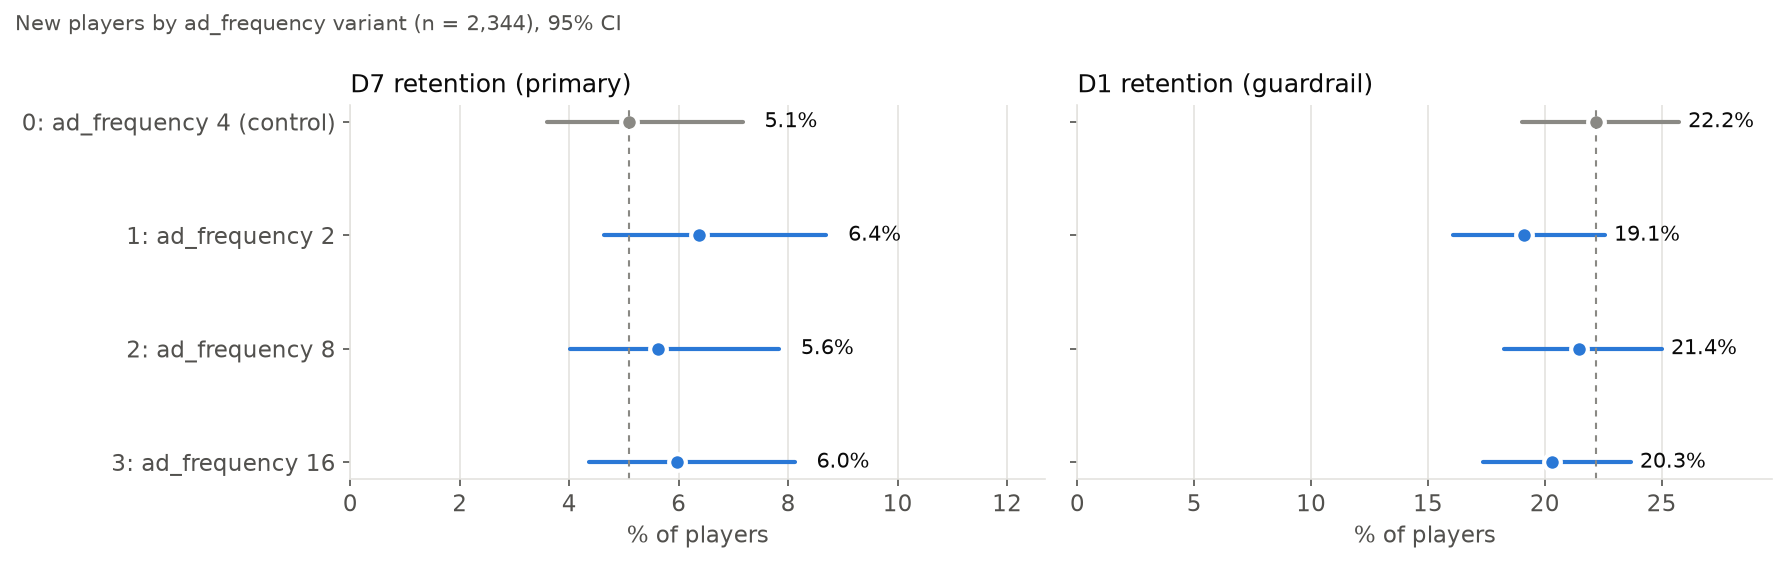

In [13]:
from statsmodels.stats.proportion import proportion_confint

INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
SERIES, CONTROL = '#2a78d6', '#8a8984'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 150})

def retention_panel(ax, pop, metric, title):
    g = pop.groupby('variant')[metric].agg(['sum', 'size'])
    rates = g['sum'] / g['size'] * 100
    lo, hi = proportion_confint(g['sum'], g['size'], method='wilson')
    ys = np.arange(len(g))[::-1]
    for y, v in zip(ys, g.index):
        color = CONTROL if v == 0 else SERIES
        ax.plot([lo[v] * 100, hi[v] * 100], [y, y], color=color, lw=2, solid_capstyle='round')
        ax.plot(rates[v], y, 'o', ms=8, color=color, mec='white', mew=2)
        ax.text(hi[v] * 100 + 0.4, y, f'{rates[v]:.1f}%', va='center', color=INK, fontsize=10)
    ax.axvline(rates[0], color=CONTROL, lw=1, ls=(0, (3, 3)))
    ax.set_yticks(ys, [VARIANT_LABEL[v] for v in g.index])
    ax.set_xlabel('% of players')
    ax.set_title(title, loc='left', color=INK, fontsize=12)
    ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_xlim(0, max(hi * 100) + 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
retention_panel(axes[0], pop_a, 'd7', 'D7 retention (primary)')
retention_panel(axes[1], pop_a, 'd1', 'D1 retention (guardrail)')
fig.suptitle(f'New players by ad_frequency variant (n = {len(pop_a):,}), 95% CI', x=0.01, ha='left',
             color=MUTED, fontsize=10)
fig.tight_layout()
fig.savefig('../figures/retention_by_variant.png', bbox_inches='tight')

## 8. Conclusion

- **The experiment is healthy.** No SRM (p = 0.56 on all 4,924 participants, p = 0.36 on new players),
  `initial_extra_steps` and the share of new players are balanced, new players got their assigned value.
- **No detectable effect of ad frequency.** On 2,344 new players, D7 is 5.1% in control and 5.6–6.4%
  in the treatments; every difference has a 95% CI that includes zero (Holm-adjusted p = 1.0).
  D1 (19.1–22.2%) and minutes played in week 1 (median 3.1–3.7 min) also show no significant change.
  The same holds for all participants (ITT) and per-protocol.
- **The test was too small to answer the question.** With about 570 new players per variant and D7 near 5%,
  the MDE is about **4.3 pp**: only a near-doubling of D7 would have been detected. To detect ±1 pp,
  about **8,300 new players per variant** would be needed (about 15× more).
- **Recommendation.** Do not ship a change based on this test. Keep the current `ad_frequency` (4),
  and if ad frequency matters for revenue, rerun with fewer variants (control vs one alternative),
  a pre-computed sample size, and ad impressions/revenue tracked so the trade-off can be measured.
- **Watch:** the most-ads variant (2) has the lowest D1 (−3.1 pp, CI −7.7 to +1.6). Not significant,
  but it is the direction a follow-up test should check first.

In [14]:
d7_a.round(2).to_csv('../results/d7_new_players.csv', index=False)
d1_a.round(2).to_csv('../results/d1_new_players.csv', index=False)
minutes_a.round(3).to_csv('../results/minutes_new_players.csv', index=False)
mde.round(2).to_csv('../results/mde.csv', index=False)
sens.round(3).to_csv('../results/sensitivity_d7.csv', index=False)